# ❤️ Heart Disease Detective: What really causes heart disease in this data?
### Data Analytics project with Python (pandas, matplotlib, seaborn, scikit-learn)

---
## 1. The Story
A hospital gives us records of **50,000 patients**. About half of them have heart disease.
Our job is to act like a **data detective 🕵️**: find out which factors are linked to heart disease, and which are not.

### Questions we will answer
| # | Question |
|---|---|
| Q1 | How many patients have heart disease? |
| Q2 | Do **lifestyle** factors (smoking, alcohol, diet, exercise, stress) matter? |
| Q3 | Do **medical conditions** (blood pressure, diabetes, past heart attack) matter? |
| Q4 | How do **age** and **cholesterol** affect risk? |
| Q5 | Can we find a **simple rule** that predicts heart disease? |

### Dataset: `heart.csv` (one row = one patient)
| Column | Meaning |
|---|---|
| Age, Gender, Weight (kg), Height (cm), BMI | Body info |
| Smoking, Alcohol_Intake, Physical_Activity, Diet, Stress_Level | Lifestyle |
| Hypertension, Diabetes, Hyperlipidemia, Family_History, Previous_Heart_Attack | Medical history (1 = Yes, 0 = No) |
| Systolic_BP, Diastolic_BP, Heart_Rate, Blood_Sugar_Fasting, Cholesterol_Total | Test results |
| **Heart_Disease** | **Target:** 1 = has heart disease, 0 = no |

> ℹ️ This is **not** the famous Kaggle "Heart Failure Prediction" dataset (that one has only 918 rows and 12 columns). This file has 50,000 rows, and we will discover that it is most likely **synthetic (computer-generated)** data.

## 2. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

BLUE, ORANGE, GREEN, YELLOW, PINK, DGREEN, VIOLET, RED = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
HEALTHY, SICK = BLUE, RED                 # same meaning, same colour, in every chart
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "grid.color": "#e6e6e3"})
PCT = mtick.PercentFormatter(1.0)

## 3. Load the Data (and a sneaky trap 🪤)
Pandas automatically turns the text **"None"** into a *missing value* (NaN).
But in `Alcohol_Intake`, "None" is a real answer: it means *the person does not drink*. Watch:

In [2]:
wrong = pd.read_csv("heart.csv")
print("Default read  -> missing Alcohol values:", wrong["Alcohol_Intake"].isna().sum())

df = pd.read_csv("heart.csv", keep_default_na=False)      # keep "None" as text
print("Correct read  -> missing Alcohol values:", (df["Alcohol_Intake"] == "").sum())
print(df["Alcohol_Intake"].value_counts())

Default read  -> missing Alcohol values: 20109
Correct read  -> missing Alcohol values: 0
Alcohol_Intake
None        20109
Low         14913
Moderate     9895
High         5083
Name: count, dtype: int64


**Lesson:** With the default `read_csv`, **20,109 "None" answers (40% of the data!) became missing values**. The old notebook then filled them with "No", which happens to give the right meaning, but by luck.
Using `keep_default_na=False` keeps "None" as real text from the start. **Always check what "missing" really means before you fill it.**

In [3]:
print("Shape:", df.shape)
df.head()

Shape: (50000, 21)


,Age,Gender,Weight,Height,BMI,Smoking,Alcohol_Intake,Physical_Activity,Diet,Stress_Level,...,Diabetes,Hyperlipidemia,Family_History,Previous_Heart_Attack,Systolic_BP,Diastolic_BP,Heart_Rate,Blood_Sugar_Fasting,Cholesterol_Total,Heart_Disease
0,48,Male,78,157,26.4,Never,None,Sedentary,Healthy,Medium,...,0,1,1,0,104,99,71,165,200,0
1,35,Female,73,163,33.0,Never,Low,Active,Average,High,...,0,1,1,0,111,72,60,145,206,0
2,79,Female,88,152,32.3,Never,None,Moderate,Average,Medium,...,0,0,1,0,116,102,78,148,208,0
3,75,Male,106,171,37.4,Never,Moderate,Moderate,Average,Low,...,0,1,0,0,171,92,109,105,290,1
4,34,Female,65,191,18.5,Current,None,Sedentary,Healthy,Low,...,1,0,0,0,164,67,108,116,220,1


In [4]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,50000.0,54.5,14.4,30.0,42.0,54.0,67.0,79.0
Weight,50000.0,84.5,20.2,50.0,67.0,85.0,102.0,119.0
Height,50000.0,174.5,14.4,150.0,162.0,174.0,187.0,199.0
BMI,50000.0,29.0,6.4,18.0,23.5,29.0,34.5,40.0
Hypertension,50000.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0
Diabetes,50000.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0
Hyperlipidemia,50000.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
Family_History,50000.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
Previous_Heart_Attack,50000.0,0.1,0.3,0.0,0.0,0.0,0.0,1.0
Systolic_BP,50000.0,139.3,23.1,100.0,119.0,139.0,159.0,179.0


**What we see:** 
- **50,000 patients and 21 columns.**
- Ages run from **30 to 79**, so there are no young people or very old patients.
- The ranges look **suspiciously neat**: cholesterol is exactly 150–299, heart rate exactly 60–109, blood sugar exactly 70–179. Real hospital data has odd extreme values and typing mistakes. This is our first clue 🕵️.

## 4. Data Quality Check 🔍

In [5]:
print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())

# Check 1: BMI should equal weight / height²
bmi_calc = df["Weight"] / (df["Height"] / 100) ** 2
diff = (bmi_calc - df["BMI"]).abs()
print(f"\nBMI check: only {(diff < 1).mean():.0%} of rows match weight/height² (within 1 point)")
print(df.assign(BMI_calculated=bmi_calc.round(1))[["Weight", "Height", "BMI", "BMI_calculated"]].head(3))

# Check 2: diastolic (lower) BP should be smaller than systolic (upper) BP
bad_bp = (df["Diastolic_BP"] >= df["Systolic_BP"]).sum()
print(f"\nRows where diastolic BP >= systolic BP (medically impossible): {bad_bp:,}")

Missing values : 0
Duplicate rows : 0

BMI check: only 7% of rows match weight/height² (within 1 point)
   Weight  Height   BMI  BMI_calculated
0      78     157  26.4            31.6
1      73     163  33.0            27.5
2      88     152  32.3            38.1



Rows where diastolic BP >= systolic BP (medically impossible): 2,235


**Findings:** 
- ✅ No missing values and no duplicate rows.
- ❌ **BMI is wrong in 93% of rows.** Example: 78 kg and 157 cm should give a BMI of **31.6**, but the file says 26.4. So the BMI column was **not calculated from weight and height**.
- ❌ **2,235 patients have their lower BP (diastolic) at or above their upper BP (systolic).** That is impossible in a real body.
- Together these mean the columns were filled in **separately and at random**, which is clue #2 that the data is synthetic.

### Plot 1 · Histograms: The shape of every number column

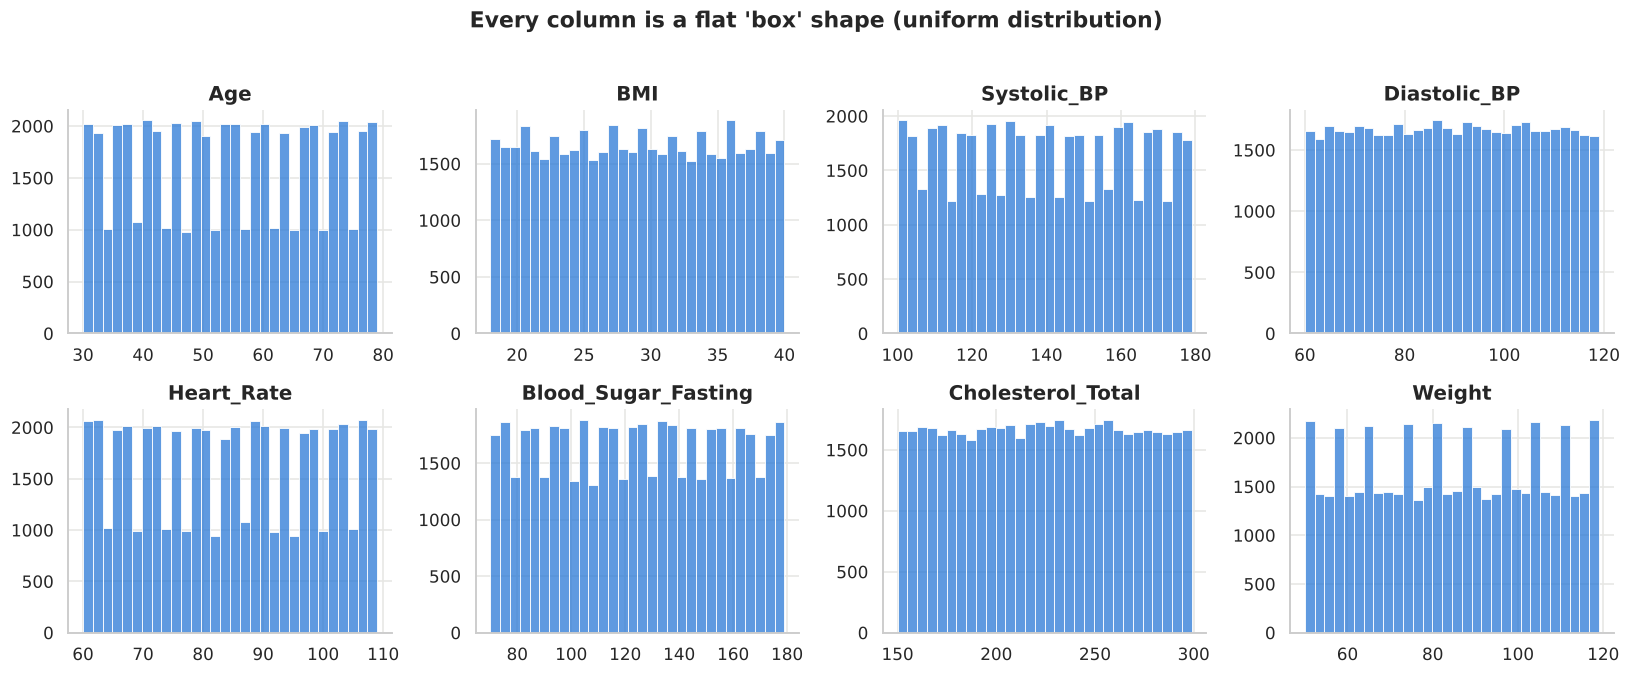

In [6]:
num_cols = ["Age", "BMI", "Systolic_BP", "Diastolic_BP", "Heart_Rate", "Blood_Sugar_Fasting", "Cholesterol_Total", "Weight"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, color=BLUE, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Every column is a flat 'box' shape (uniform distribution)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**Interpretation:** 
- Real body measurements look like a **bell curve** (most people in the middle, few at the extremes).
- Here **every column is flat, like a box**: there are as many 30-year-olds as 79-year-olds, and as many people with cholesterol 150 as 299.
- (The small gaps in some histograms appear only because the values are whole numbers.)
- **Clue #3:** a flat (uniform) shape is what a computer gives when it picks random numbers. **Conclusion: this is synthetic data.** It is still excellent for practice, but we must not use it to give real medical advice.

In [7]:
# Small cleaning for nicer charts
df["Gender"] = df["Gender"].str.strip()
yes_no = ["Hypertension", "Diabetes", "Hyperlipidemia", "Family_History", "Previous_Heart_Attack"]
df["Status"] = df["Heart_Disease"].map({0: "Healthy", 1: "Heart Disease"})
df["Age_Group"] = pd.cut(df["Age"], bins=[29, 39, 49, 59, 69, 79], labels=["30s", "40s", "50s", "60s", "70s"])
print("Ready ✔")

Ready ✔


---
## 5. How many patients are sick? (Q1)
### Plot 2 · Donut chart

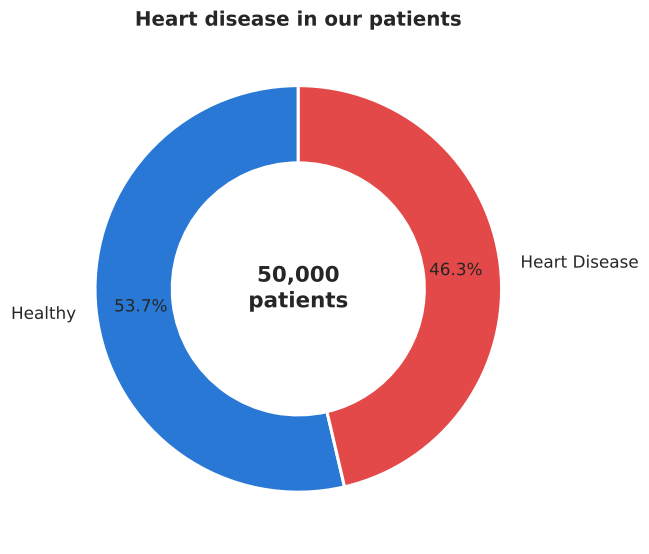

Overall heart disease rate = 46.3%  ← we compare everything against this number


In [8]:
counts = df["Status"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=[HEALTHY, SICK], pctdistance=.78,
       wedgeprops=dict(width=.38, edgecolor="white", linewidth=2), textprops=dict(fontsize=11))
ax.text(0, 0, f"{len(df):,}\npatients", ha="center", va="center", fontsize=14, fontweight="bold")
ax.set_title("Heart disease in our patients"); plt.show()
BASE = df["Heart_Disease"].mean()
print(f"Overall heart disease rate = {BASE:.1%}  ← we compare everything against this number")

**Interpretation:** 
- **46.3% of patients have heart disease** and 53.7% are healthy.
- The two classes are **almost balanced**, which is good for machine learning (no serious class imbalance problem).
- 💡 **46.3% is our "baseline".** Any group well above 46% is at higher risk, and any group well below is at lower risk.

---
## 6. The Count Trap ⚠️ (very important lesson)
### Plot 3 · Counts vs Percentages: Smoking

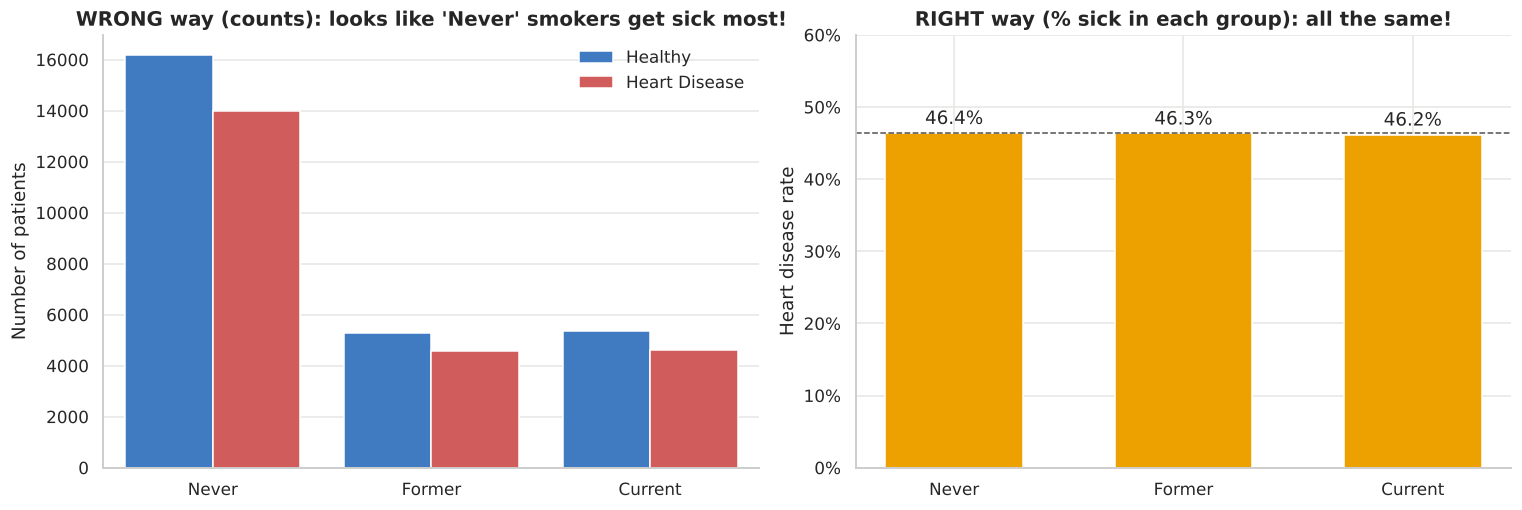

Smoking
Never      30160
Current     9965
Former      9875


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.countplot(data=df, x="Smoking", hue="Status", palette=[HEALTHY, SICK], order=["Never", "Former", "Current"], ax=axes[0])
axes[0].set(title="WRONG way (counts): looks like 'Never' smokers get sick most!", xlabel="", ylabel="Number of patients")
axes[0].legend(title="", frameon=False)

rate = df.groupby("Smoking")["Heart_Disease"].mean().reindex(["Never", "Former", "Current"])
bars = axes[1].bar(rate.index, rate.values, color=YELLOW, width=.6)
axes[1].bar_label(bars, labels=[f"{v:.1%}" for v in rate], padding=3)
axes[1].axhline(BASE, color="#52514e", ls="--", lw=1)
axes[1].yaxis.set_major_formatter(PCT); axes[1].set_ylim(0, .6)
axes[1].set(title="RIGHT way (% sick in each group): all the same!", xlabel="", ylabel="Heart disease rate")
plt.tight_layout(); plt.show()
print(df["Smoking"].value_counts().to_string())

**Interpretation:** 
**This is the most common beginner mistake in data analysis!**
- **Left chart (counts):** "Never smokers" have the tallest red bar. You might think *not smoking causes heart disease* 🤯.
- But that bar is tall only because **Never smokers are the biggest group (30,160 people, 60%)**. More people means more sick people.
- **Right chart (percentages):** **46.4% vs 46.3% vs 46.2%**, exactly the same in every group.
- **Rule: when groups have different sizes, compare percentages (rates), not counts.** The old notebook used count plots and fell into this trap.

---
## 7. Does lifestyle matter? (Q2)
### Plot 4 · Small multiples: Heart disease rate for every lifestyle factor

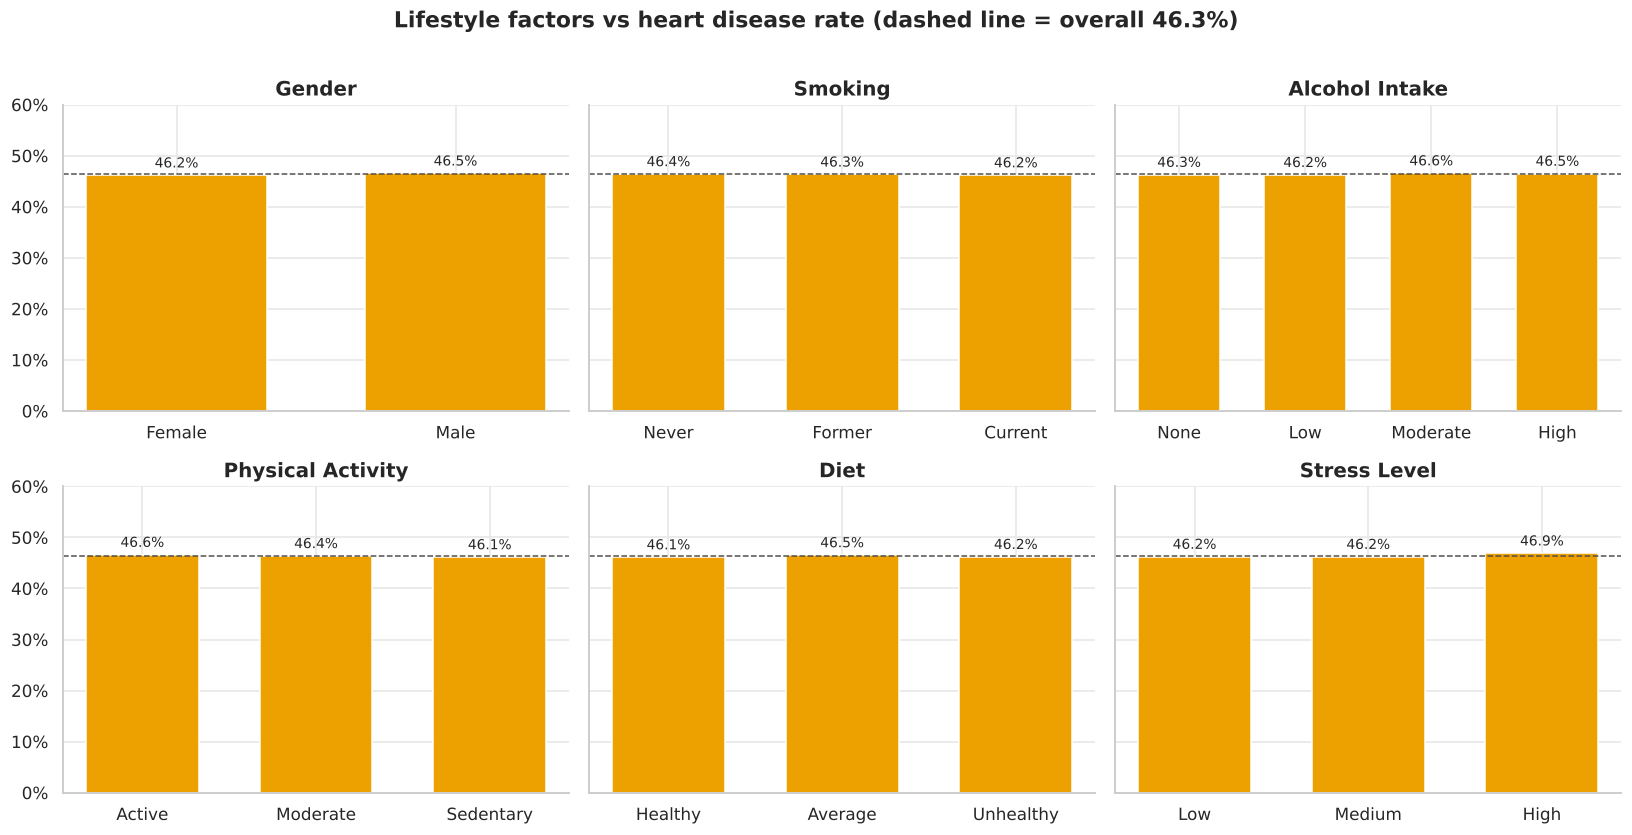

In [10]:
life = {"Gender": ["Female", "Male"], "Smoking": ["Never", "Former", "Current"],
        "Alcohol_Intake": ["None", "Low", "Moderate", "High"], "Physical_Activity": ["Active", "Moderate", "Sedentary"],
        "Diet": ["Healthy", "Average", "Unhealthy"], "Stress_Level": ["Low", "Medium", "High"]}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for ax, (col, order) in zip(axes.flat, life.items()):
    r = df.groupby(col)["Heart_Disease"].mean().reindex(order)
    b = ax.bar(r.index, r.values, color=YELLOW, width=.65)
    ax.bar_label(b, labels=[f"{v:.1%}" for v in r], padding=3, fontsize=9)
    ax.axhline(BASE, color="#52514e", ls="--", lw=1)
    ax.set(title=col.replace("_", " "), ylim=(0, .6), xlabel=""); ax.yaxis.set_major_formatter(PCT)
fig.suptitle("Lifestyle factors vs heart disease rate (dashed line = overall 46.3%)", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**Interpretation:** 
**Surprise! None of the lifestyle factors make any difference in this data.**
- Every bar sits right on the 46% line. Gender, smoking, alcohol, exercise, diet and stress all give **46.1%–46.9%**.
- ⚠️ In **real life**, smoking, an unhealthy diet and inactivity **are** proven causes of heart disease (WHO). This dataset ignores them because it was generated by a simple computer rule (we will find that rule in Section 10).
- **Lesson:** an analysis is only as true as its data. Always ask *"does this match real-world knowledge?"*

---
## 8. Do medical conditions matter? (Q3)
### Plot 5 · Grouped bars: Rate with vs without each condition

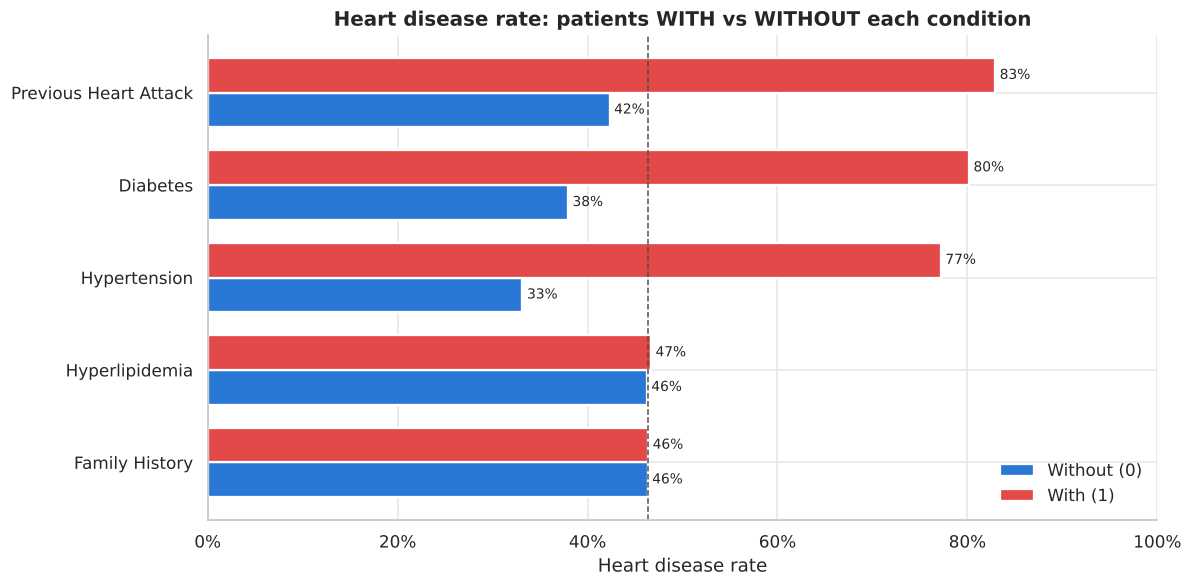

,Without (0),With (1),How many times higher
Condition,,,
Family History,0.463,0.464,1.00
Hyperlipidemia,0.462,0.467,1.01
Hypertension,0.331,0.772,2.33
Diabetes,0.379,0.802,2.11
Previous Heart Attack,0.423,0.829,1.96


In [11]:
rows = []
for col in yes_no:
    r = df.groupby(col)["Heart_Disease"].mean()
    rows.append({"Condition": col.replace("_", " "), "Without (0)": r[0], "With (1)": r[1]})
med = pd.DataFrame(rows).set_index("Condition").sort_values("With (1)")
ax = med.plot.barh(color=[BLUE, RED], width=.75, figsize=(11, 5.5), edgecolor="white", linewidth=1.5)
for c in ax.containers: ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], padding=3, fontsize=9)
ax.axvline(BASE, color="#52514e", ls="--", lw=1)
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1)
ax.set(title="Heart disease rate: patients WITH vs WITHOUT each condition", xlabel="Heart disease rate", ylabel="")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
med["How many times higher"] = (med["With (1)"] / med["Without (0)"]).round(2)
med.round(3)

**Interpretation:** 
**Here we finally find big differences 🎯**
- **Hypertension (high BP):** 77% sick with it vs 33% without, **2.3× higher risk**.
- **Diabetes:** 80% vs 38%, **2.1× higher**.
- **Previous heart attack:** 83% vs 42%, **about 2× higher**.
- **Family history and hyperlipidemia: no effect (46% vs 46%).** That is strange, because hyperlipidemia means "high cholesterol", yet the cholesterol *test* matters a lot (Plot 8). Another sign of synthetic data.

### Plot 6 · Heatmap: What if a patient has BOTH hypertension and diabetes?

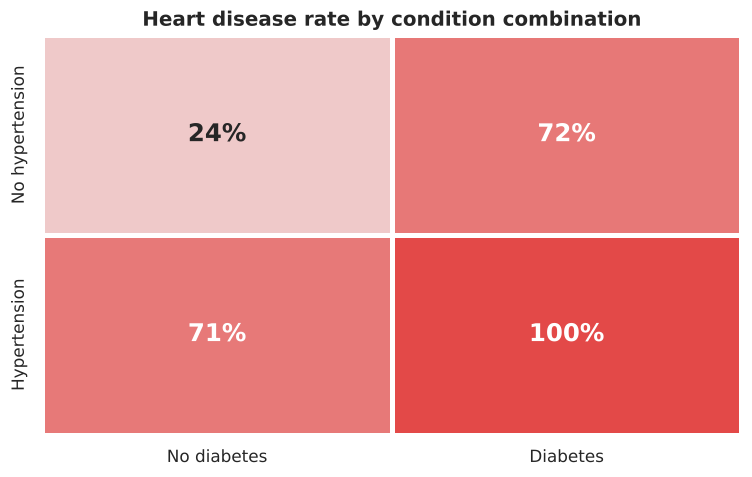

In [12]:
combo = pd.crosstab(df["Hypertension"].map({0: "No hypertension", 1: "Hypertension"}),
                    df["Diabetes"].map({0: "No diabetes", 1: "Diabetes"}), values=df["Heart_Disease"], aggfunc="mean")
combo = combo.loc[["No hypertension", "Hypertension"], ["No diabetes", "Diabetes"]]
plt.figure(figsize=(7, 4.5))
sns.heatmap(combo, annot=True, fmt=".0%", cmap=sns.light_palette(RED, as_cmap=True), vmin=0, vmax=1,
            linewidths=3, linecolor="white", annot_kws={"fontsize": 16, "fontweight": "bold"}, cbar=False)
plt.title("Heart disease rate by condition combination"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

**Interpretation:** 
- **No hypertension + no diabetes → 24%** (low risk).
- **Only one of them → about 71–72%** (high risk).
- **Both → 100%! Every single patient with both is sick.**
- In this data, risk factors **stack up**. This hints at the hidden rule: having **two** risk factors seems to guarantee heart disease.

---
## 9. Age and Cholesterol (Q4)
### Plot 7 · Line chart: Heart disease rate at every age

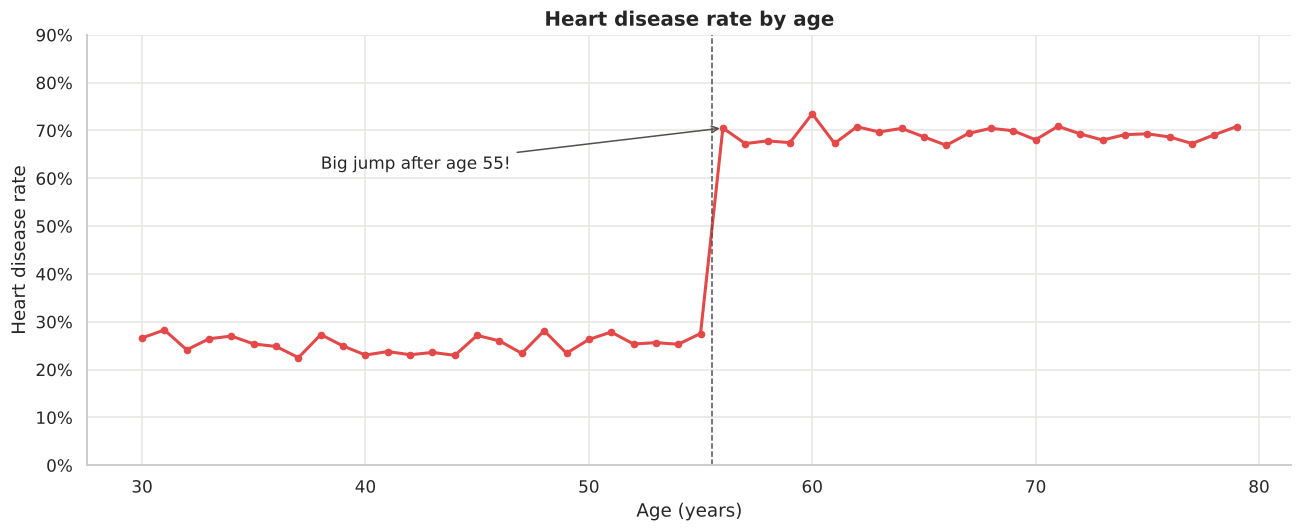

Age 55 and below: 25%  |  Above 55: 69%


In [13]:
age_rate = df.groupby("Age")["Heart_Disease"].mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(age_rate.index, age_rate.values, marker="o", ms=4, lw=2, color=RED)
ax.axvline(55.5, color="#52514e", ls="--", lw=1)
ax.annotate("Big jump after age 55!", xy=(56, age_rate[56]), xytext=(38, .62), fontsize=11,
            arrowprops=dict(arrowstyle="->", color="#52514e"))
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, .9)
ax.set(title="Heart disease rate by age", xlabel="Age (years)", ylabel="Heart disease rate")
plt.tight_layout(); plt.show()
print(f"Age 55 and below: {df[df.Age <= 55].Heart_Disease.mean():.0%}  |  Above 55: {df[df.Age > 55].Heart_Disease.mean():.0%}")

**Interpretation:** 
- Look at the shape: it is **not a smooth rise**. It is a **step** 📶.
- **Up to age 55: about 25% risk. From age 56: about 69% risk.** The rate jumps overnight between 55 and 56.
- In real life risk rises gradually with age. A sudden cliff like this shows a **computer rule like `if age > 55`**.

### Plot 8 · Bar chart: Heart disease rate by cholesterol level

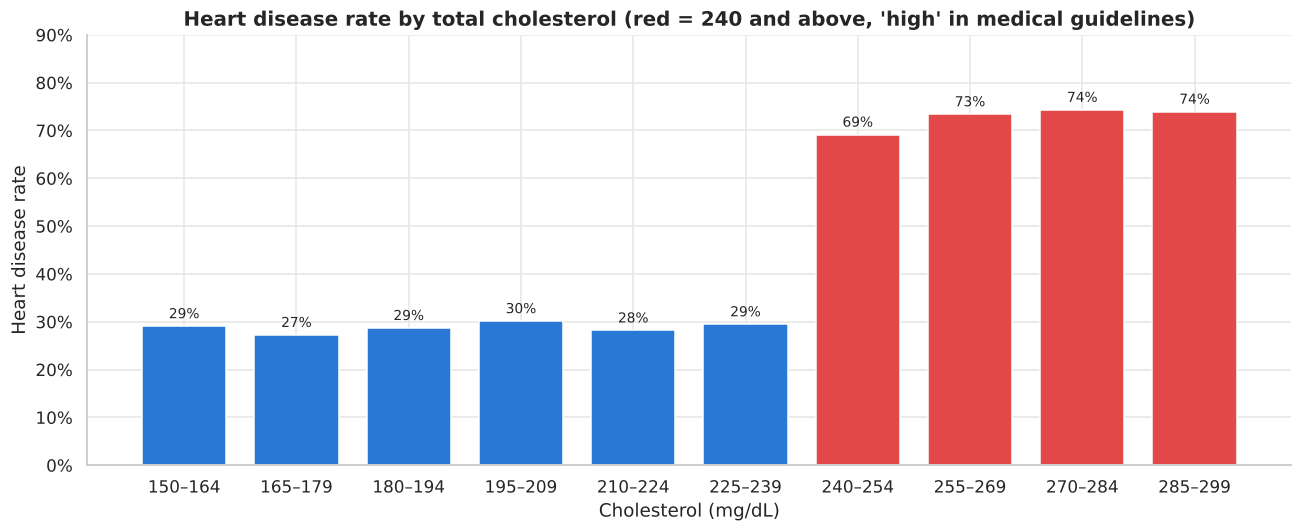

Cholesterol ≤ 240: 29%  |  > 240: 74%


In [14]:
df["Chol_Band"] = pd.cut(df["Cholesterol_Total"], bins=range(150, 301, 15), right=False)
ch = df.groupby("Chol_Band", observed=True)["Heart_Disease"].mean()
colors = [RED if b.left >= 240 else BLUE for b in ch.index]
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar([f"{b.left}–{b.right-1}" for b in ch.index], ch.values, color=colors, width=.75)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in ch], padding=3, fontsize=9)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, .9)
ax.set(title="Heart disease rate by total cholesterol (red = 240 and above, 'high' in medical guidelines)",
       xlabel="Cholesterol (mg/dL)", ylabel="Heart disease rate")
plt.tight_layout(); plt.show()
print(f"Cholesterol ≤ 240: {df[df.Cholesterol_Total <= 240].Heart_Disease.mean():.0%}  |  > 240: {df[df.Cholesterol_Total > 240].Heart_Disease.mean():.0%}")

**Interpretation:** 
- Again a **step, not a slope**: about **29% risk up to 239**, then **69–74% from 240 upward**.
- **240 mg/dL is the official "high cholesterol" level** in medical guidelines, so the data creator used that exact cut-off.
- **Cholesterol ≤ 240: 29% sick, above 240: 74% sick.**

### Plot 9 · KDE plots: Which test results separate sick from healthy?

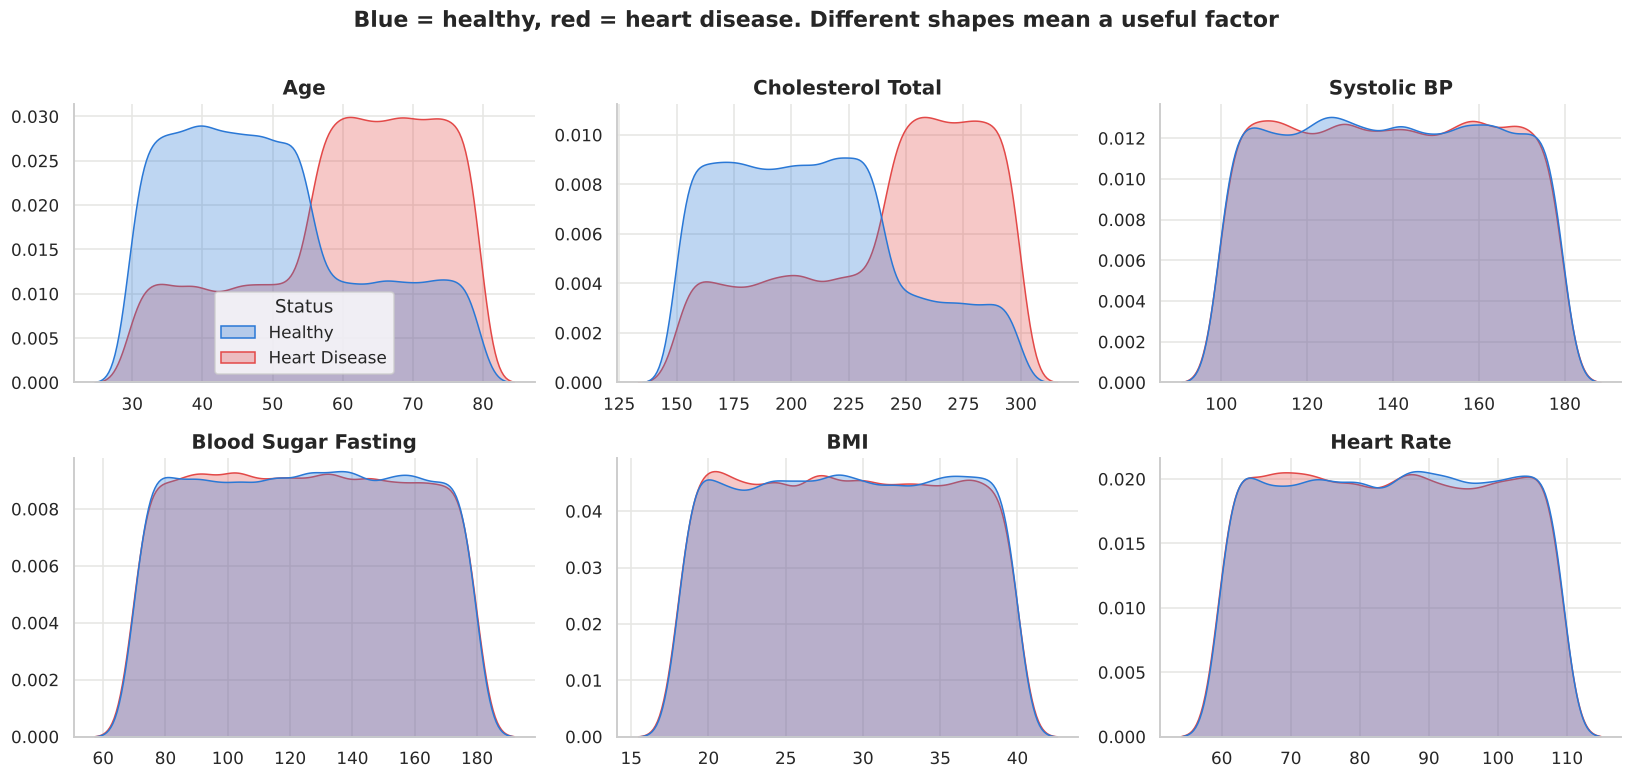

In [15]:
tests = ["Age", "Cholesterol_Total", "Systolic_BP", "Blood_Sugar_Fasting", "BMI", "Heart_Rate"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, tests):
    sns.kdeplot(data=df, x=col, hue="Status", palette=[HEALTHY, SICK], fill=True, alpha=.3, common_norm=False, ax=ax, legend=(col == "Age"))
    ax.set(title=col.replace("_", " "), xlabel="", ylabel="")
fig.suptitle("Blue = healthy, red = heart disease. Different shapes mean a useful factor", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**Interpretation:** 
- **Age and cholesterol:** the blue (healthy) and red (sick) shapes are **clearly different**. Sick patients bunch on the right (older age, higher cholesterol). These are useful predictors ✅.
- **Blood pressure readings, blood sugar, BMI, heart rate:** blue and red lie **exactly on top of each other**, so they carry no information ❌.
- Interesting: the *hypertension* flag (yes/no) matters, but the actual *systolic BP number* does not. In real data they would go together.

### Plot 10 · Violin plots: Age and cholesterol, healthy vs sick

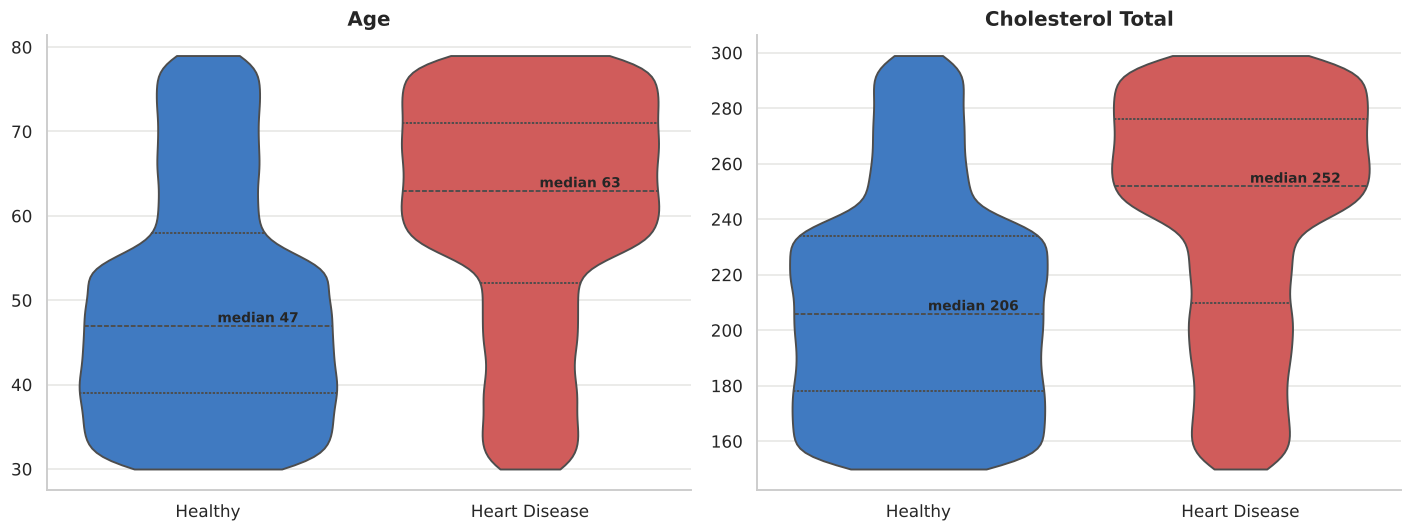

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, ["Age", "Cholesterol_Total"]):
    sns.violinplot(data=df, x="Status", y=col, palette=[HEALTHY, SICK], inner="quartile", cut=0, ax=ax, order=["Healthy", "Heart Disease"])
    med_vals = df.groupby("Status")[col].median()
    for i, s in enumerate(["Healthy", "Heart Disease"]):
        ax.text(i, med_vals[s], f"  median {med_vals[s]:.0f}", va="bottom", fontsize=9, fontweight="bold")
    ax.set(title=col.replace("_", " "), xlabel="", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** 
- A violin is a box plot plus its shape. Wide parts = many patients.
- **Age:** median **47 for healthy vs 63 for sick**. The sick violin is fat at the top (old ages).
- **Cholesterol:** median **206 vs 252**. The sick violin is fat above 240.
- Notice the "waist" in each violin near **55 years** and **240 cholesterol**: those are the cut-off points again.

### Plot 11 · Bar chart: Correlation of every column with heart disease

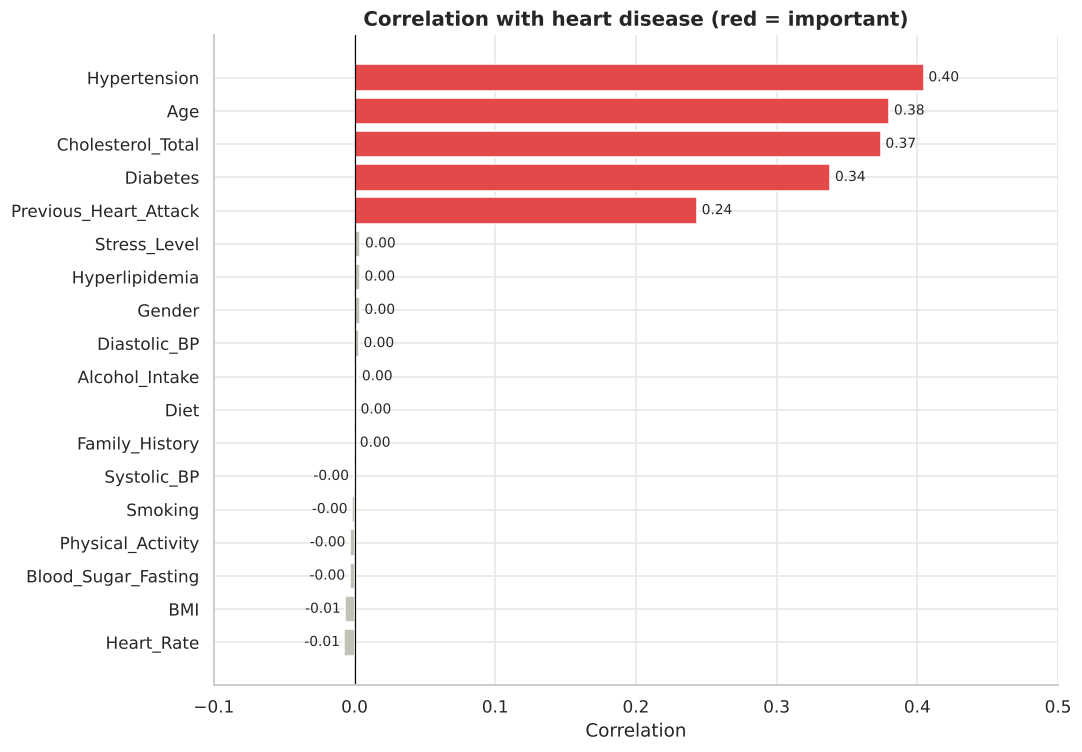

In [17]:
enc = df.copy()
for col, order in life.items():
    enc[col] = enc[col].map({v: i for i, v in enumerate(order)})     # turn text into 0, 1, 2...
features = ["Age", "Gender", "BMI", "Smoking", "Alcohol_Intake", "Physical_Activity", "Diet", "Stress_Level"] + yes_no + \
           ["Systolic_BP", "Diastolic_BP", "Heart_Rate", "Blood_Sugar_Fasting", "Cholesterol_Total"]
corr = enc[features + ["Heart_Disease"]].corr()["Heart_Disease"].drop("Heart_Disease").sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(corr.index, corr.values, color=[RED if abs(v) > .1 else "#c3c2b7" for v in corr])
ax.bar_label(bars, labels=[f"{v:.2f}" for v in corr], padding=3, fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=.8); ax.set_xlim(-.1, .5)
ax.set(title="Correlation with heart disease (red = important)", xlabel="Correlation", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** 
- Correlation goes from −1 to +1. Near 0 = no relationship.
- **Only 5 columns matter:** Hypertension (0.40), Age (0.38), Cholesterol (0.37), Diabetes (0.34), Previous Heart Attack (0.24).
- **All other 16 columns are at about 0.00.** They are pure noise.
- This single chart is clearer than a big 20×20 heatmap without numbers (which the old notebook used).

---
## 10. Cracking the Code 🔓 (Q5)
We found **5 suspects**: age above 55, cholesterol above 240, hypertension, diabetes, and a previous heart attack.
Let's count how many of these 5 risk factors each patient has.

### Plot 12 · Bar chart: Number of risk factors vs heart disease

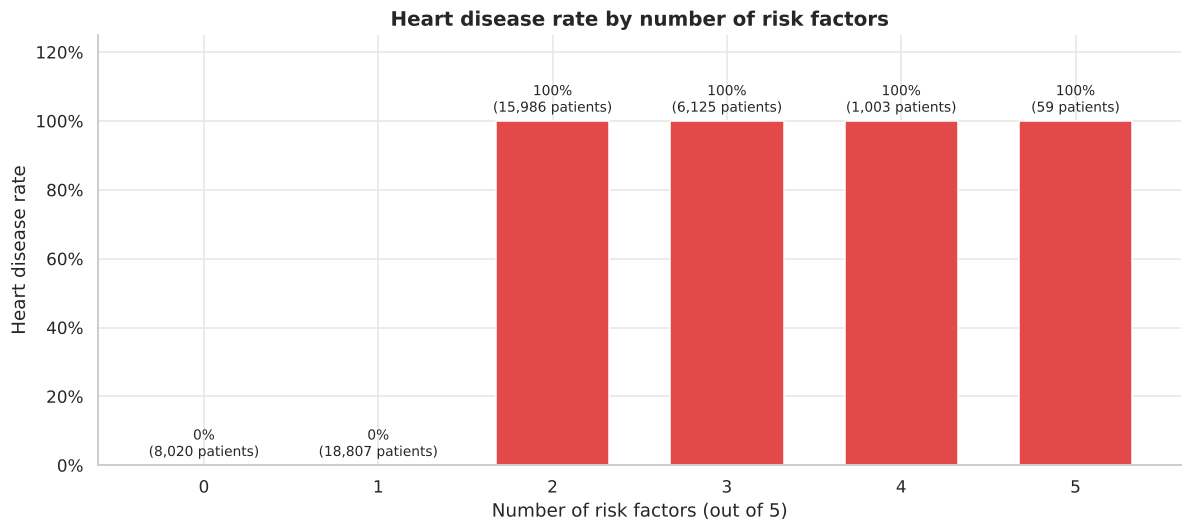

Rule 'sick if 2 or more risk factors' is correct for 100.0% of patients!


In [18]:
df["Risk_Count"] = ((df["Age"] > 55).astype(int) + (df["Cholesterol_Total"] > 240).astype(int)
                    + df["Hypertension"] + df["Diabetes"] + df["Previous_Heart_Attack"])
rc = df.groupby("Risk_Count")["Heart_Disease"].agg(rate="mean", patients="size")
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(rc.index.astype(str), rc.rate, color=[BLUE if v < .5 else RED for v in rc.rate], width=.65)
ax.bar_label(bars, labels=[f"{r:.0%}\n({n:,} patients)" for r, n in zip(rc.rate, rc.patients)], padding=3, fontsize=9)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 1.25)
ax.set(title="Heart disease rate by number of risk factors", xlabel="Number of risk factors (out of 5)", ylabel="Heart disease rate")
plt.tight_layout(); plt.show()
rule = (df["Risk_Count"] >= 2).astype(int)
print(f"Rule 'sick if 2 or more risk factors' is correct for {(rule == df.Heart_Disease).mean():.1%} of patients!")

**Interpretation:** 
**🔓 Case solved!** This is the hidden rule the computer used to create the data:
> **A patient has heart disease if they have 2 or more of these 5 risk factors:** age above 55, cholesterol above 240, hypertension, diabetes, previous heart attack.
- **0 or 1 risk factor → 0% sick. 2 or more → 100% sick.** No exceptions at all.
- Our simple rule is **100% correct** for all 50,000 patients.
- Real diseases never follow a perfect rule. This proves the data is synthetic, but it also shows how **good analysis can reveal the logic hidden inside data**.

### Plot 13 · Decision tree: Let a machine learning model find the rule by itself

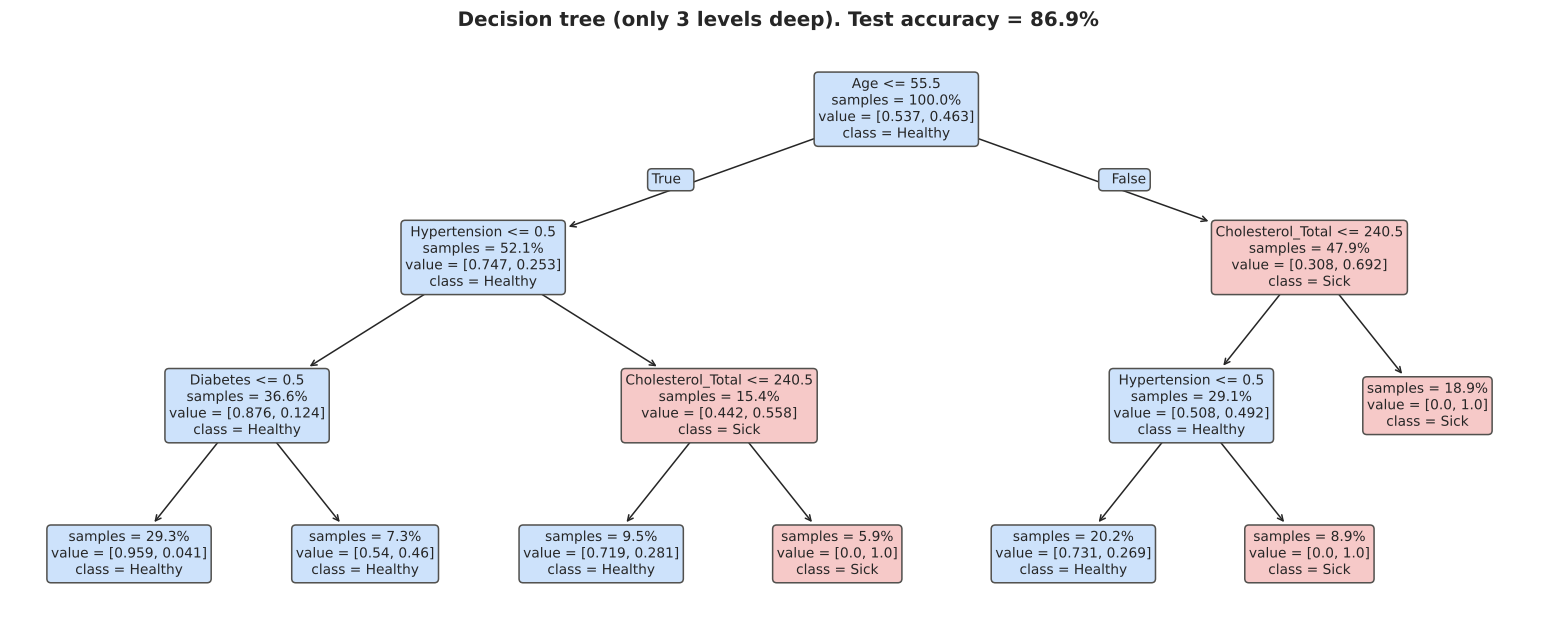

In [19]:
X = pd.get_dummies(df[features].drop(columns=list(life)).join(df[list(life)]), drop_first=True)
y = df["Heart_Disease"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
acc = accuracy_score(y_test, tree.predict(X_test))
plt.figure(figsize=(18, 7))
nodes = plot_tree(tree, feature_names=X.columns, class_names=["Healthy", "Sick"], filled=False, rounded=True,
                  impurity=False, proportion=True, fontsize=9)
for n in nodes:                                   # colour boxes: red = predicts Sick, blue = predicts Healthy
    n.set_bbox(dict(boxstyle="round", ec="#52514e", fc="#f6c9c8" if "class = Sick" in n.get_text() else "#cde2fb"))
plt.title(f"Decision tree (only 3 levels deep). Test accuracy = {acc:.1%}", fontweight="bold")
plt.show()

**Interpretation:** 
- A decision tree asks yes/no questions, like a flowchart. **Red boxes = predicts Sick, blue = predicts Healthy.**
- **Without being told**, the model found the same factors: its very first question is **"Age ≤ 55.5?"**, followed by Hypertension, Cholesterol ≤ 240.5 and Diabetes.
- With only 3 levels it already gets **86.9% correct**. Notice that it found exactly our cut-offs: **55.5** and **240.5**.

### Plot 14 · Feature importance & confusion matrix (deeper tree)

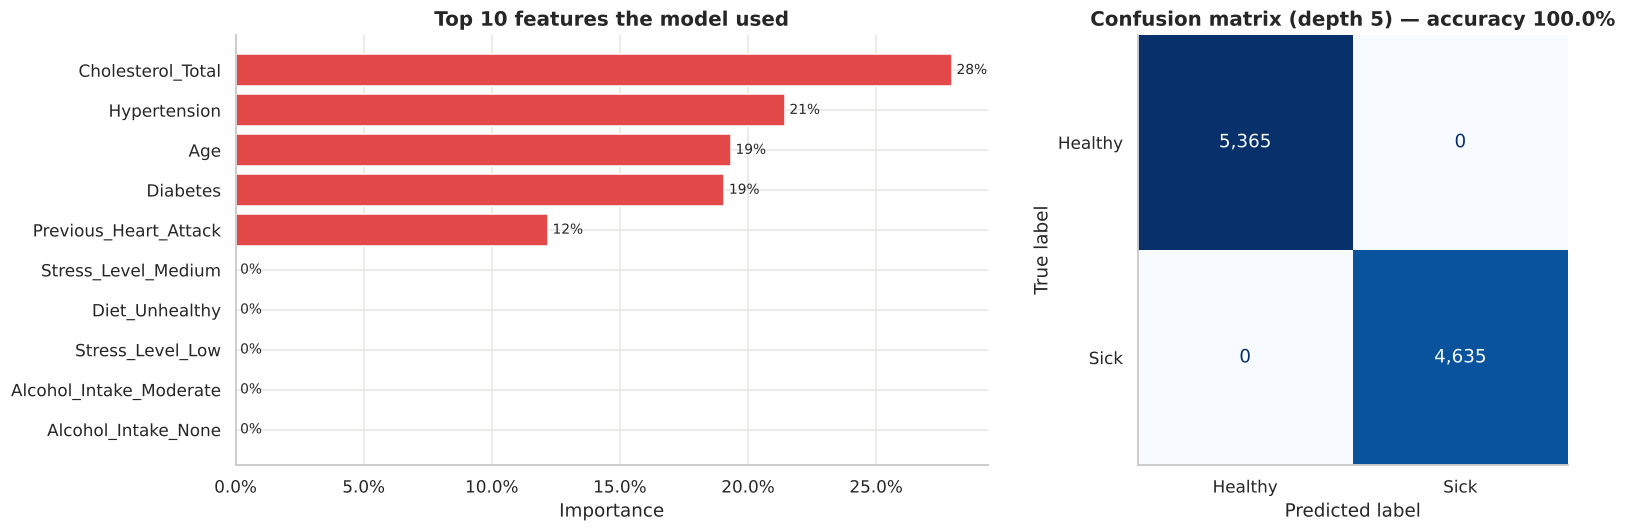

In [20]:
tree5 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
pred = tree5.predict(X_test)
imp = pd.Series(tree5.feature_importances_, X.columns).sort_values().tail(10)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})
bars = axes[0].barh(imp.index, imp.values, color=[RED if v > .01 else "#c3c2b7" for v in imp])
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in imp], padding=3, fontsize=9)
axes[0].xaxis.set_major_formatter(PCT); axes[0].set(title="Top 10 features the model used", xlabel="Importance")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Healthy", "Sick"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=",")
axes[1].set_title(f"Confusion matrix (depth 5) — accuracy {accuracy_score(y_test, pred):.1%}"); axes[1].grid(False)
plt.tight_layout(); plt.show()

**Interpretation:** 
- With 5 levels the tree reaches **100% accuracy**: zero mistakes on 10,000 test patients.
- The model uses **only the same 5 features**. Smoking, diet, stress and the rest get **0% importance**.
- ⚠️ **100% accuracy is a warning sign, not a celebration.** On real medical data, good models usually reach 75–90%. A perfect score usually means the data is synthetic, or **data leakage** (the answer is hidden inside the inputs).

---
## 11. 📋 Final Summary

### 11.1 Answers to our questions
| # | Question | Answer |
|---|---|---|
| Q1 | How many are sick? | **46.3%** (23,173 of 50,000). Classes are nearly balanced. |
| Q2 | Does lifestyle matter? | **No, not in this data.** Smoking, alcohol, diet, exercise, stress and gender all give about 46%. |
| Q3 | Medical conditions? | **Yes:** hypertension (2.3× risk), diabetes (2.1×), previous heart attack (about 2×). Family history and hyperlipidemia have no effect. |
| Q4 | Age & cholesterol? | **Sharp steps:** risk jumps from 25% to 69% after **age 55**, and from 29% to 74% above **cholesterol 240**. |
| Q5 | A simple rule? | **Yes! 2 or more of the 5 risk factors = heart disease, 100% of the time.** A decision tree found the same rule by itself. |

### 11.2 What we learned as data analysts 🎓
1. **Check how missing values are read**: "None" can be a real answer, not a missing one.
2. **Compare percentages, not counts**, when groups have different sizes (the Smoking trap).
3. **Check the data against real-world logic**: wrong BMI, impossible BP and flat distributions all showed the data is synthetic.
4. **A step in a chart means a rule**, while real biology changes gradually.
5. **100% model accuracy is a red flag**, not a win.
6. **Synthetic data is fine for learning, but never for medical decisions.** In real life smoking, diet and exercise *do* matter.

### 11.3 What was fixed compared with the first version
| Before | Now |
|---|---|
| Wrong dataset link (Kaggle Heart Failure, 918 rows) | Removed; noted the data is a different 50K-row file |
| "None" alcohol answers read as missing | Read correctly with `keep_default_na=False` |
| Count plots (misleading) | Percentage (rate) plots with a baseline line |
| Box plot of a 0/1 column (Hypertension) | Grouped rate bars and a combination heatmap |
| Heatmap with no numbers | Ranked correlation bar chart with values |
| No interpretations, empty summary | Explanation under every chart + full summary |
| No data quality checks | BMI, blood pressure and distribution checks |

### 11.4 Next steps (homework ideas)
- Try the **real** Kaggle Heart Failure dataset (918 patients) and compare. Do smoking and age behave differently there?
- Train a **Logistic Regression** model and compare it with the decision tree.
- Build a small **Streamlit app** where a user enters their values and sees their risk-factor count.